# Experiment 7: Sentiment Analysis on IMDB Movie Reviews (Logistic Regression vs LSTM vs Transformer vs BERT)

**Objective:** Classify IMDB movie reviews as *positive* or *negative* with four model families of increasing capacity, and compare them using **Precision, Recall, F1** and the **Confusion Matrix**:

| # | Model | Text representation | Learns from |
| :-: | :-- | :-- | :-- |
| 1 | Logistic Regression | Sparse TF-IDF (uni + bi-grams) | Scratch |
| 2 | LSTM (bidirectional) | Learned word embeddings + recurrence | Scratch |
| 3 | Vanilla Transformer encoder | Learned embeddings + sinusoidal positions + self-attention | Scratch |
| 4 | BERT (`bert-base-uncased`) | Contextual WordPiece embeddings | Pretrained, fine-tuned |

All four models use the **same stratified train / validation / test split**, so the metrics can be compared directly.

## 7.1 Dataset Loading and Preprocessing

In [1]:
import os, re, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

# IMDB 50K dataset (from the reference repository); downloaded once if not present locally
DATA_URL = 'https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv'
data_path = Path('IMDB-Dataset.csv')
if not data_path.exists() and Path('Experiment7').exists():
    data_path = Path('Experiment7') / 'IMDB-Dataset.csv'
if not data_path.exists():
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, data_path)

df = pd.read_csv(data_path)
print('Raw shape:', df.shape)
n_dup = df.duplicated('review').sum()
df = df.drop_duplicates('review').reset_index(drop=True)   # duplicates would leak between train and test
df['label'] = (df['sentiment'] == 'positive').astype(int)
print(f'Removed {n_dup} duplicate reviews -> {df.shape[0]} unique reviews')
print(df['sentiment'].value_counts().to_dict())
df.head(3)

Device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


Raw shape: (50000, 2)
Removed 418 duplicate reviews -> 49582 unique reviews
{'positive': 24884, 'negative': 24698}


,review,sentiment,label
0,One of the other reviewers has mentioned that ...,positive,1
1,A wonderful little production. <br /><br />The...,positive,1
2,I thought this was a wonderful way to spend ti...,positive,1


Train: 35698 | Validation: 3967 | Test: 9917
Review length (words): median = 172, 90th percentile = 449


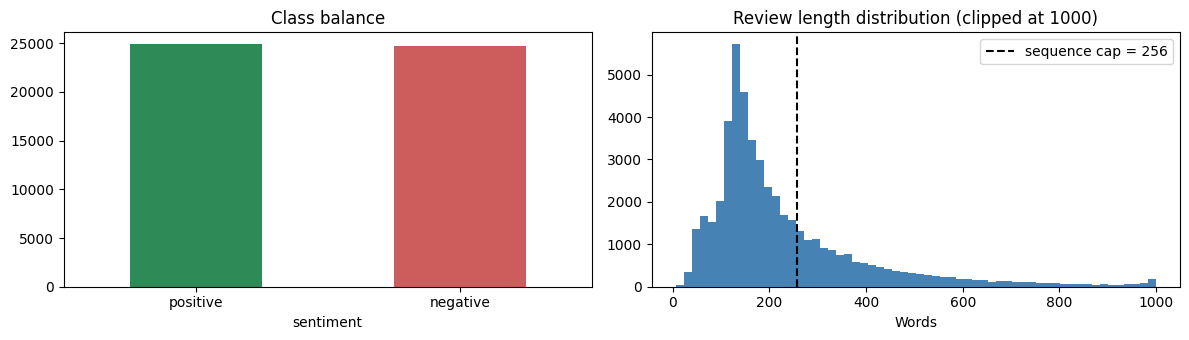

In [2]:
def strip_html(text):
    return re.sub(r'<[^>]+>', ' ', text)

def clean_text(text):
    text = strip_html(text).lower()
    text = re.sub(r"[^a-z' ]", ' ', text)     # keep letters and apostrophes (don't, isn't)
    return re.sub(r'\s+', ' ', text).strip()

df['clean'] = df['review'].apply(clean_text)
df['bert_text'] = df['review'].apply(lambda t: re.sub(r'\s+', ' ', strip_html(t)).strip())  # BERT keeps case-folding/punctuation to its tokenizer
df['n_words'] = df['clean'].str.split().str.len()

from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.1, stratify=train_df['label'], random_state=SEED)
print(f'Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}')
print(f"Review length (words): median = {df['n_words'].median():.0f}, 90th percentile = {df['n_words'].quantile(0.9):.0f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df['sentiment'].value_counts().plot.bar(ax=ax[0], color=['seagreen', 'indianred'], rot=0, title='Class balance')
ax[1].hist(df['n_words'].clip(upper=1000), bins=60, color='steelblue')
ax[1].axvline(256, color='k', ls='--', label='sequence cap = 256')
ax[1].set(title='Review length distribution (clipped at 1000)', xlabel='Words'); ax[1].legend()
plt.tight_layout(); plt.show()

y_train, y_val, y_test = train_df['label'].values, val_df['label'].values, test_df['label'].values

In [3]:
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             confusion_matrix, classification_report)

results = {}   # model name -> metrics, predictions, training time, parameter count

def record(name, y_pred, train_time, n_params):
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'Train time (s)': train_time,
        'Parameters': n_params,
        'cm': confusion_matrix(y_test, y_pred),
    }
    print(f'=== {name} (test set) ===')
    print(classification_report(y_test, y_pred, target_names=['negative', 'positive'], digits=4))

## 7.2 Logistic Regression (TF-IDF features)

Each review becomes a sparse TF-IDF vector over unigrams and bigrams; bigrams capture local negation such as *"not good"*. Logistic regression models $P(y=1\mid x)=\sigma(w^{\top}x+b)$ with L2 regularisation, so every n-gram gets one interpretable weight.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=100_000, min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(train_df['clean'])
X_test_tfidf = tfidf.transform(test_df['clean'])
logreg = LogisticRegression(C=4.0, max_iter=1000, random_state=SEED)
logreg.fit(X_train_tfidf, y_train)
lr_time = time.time() - t0
print(f'TF-IDF matrix: {X_train_tfidf.shape} | trained in {lr_time:.1f}s')

record('Logistic Regression', logreg.predict(X_test_tfidf), lr_time, logreg.coef_.size + 1)

# Interpretability: strongest n-gram weights
feat = np.array(tfidf.get_feature_names_out()); coef = logreg.coef_[0]
print('Most positive n-grams:', ', '.join(feat[np.argsort(-coef)[:12]]))
print('Most negative n-grams:', ', '.join(feat[np.argsort(coef)[:12]]))

TF-IDF matrix: (35698, 100000) | trained in 32.0s
=== Logistic Regression (test set) ===
              precision    recall  f1-score   support

    negative     0.9202    0.9008    0.9104      4940
    positive     0.9036    0.9224    0.9129      4977

    accuracy                         0.9117      9917
   macro avg     0.9119    0.9116    0.9116      9917
weighted avg     0.9118    0.9117    0.9117      9917

Most positive n-grams: great, excellent, perfect, wonderful, amazing, brilliant, today, superb, hilarious, enjoyable, loved, best


Most negative n-grams: worst, awful, bad, boring, the worst, terrible, poor, waste, nothing, horrible, worse, dull


## 7.3 Shared setup for the neural models (vocabulary, encoding, training loop)

In [5]:
from collections import Counter
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

MAX_LEN, VOCAB_SIZE, BATCH = 256, 20_000, 128
counter = Counter(w for text in train_df['clean'] for w in text.split())   # vocabulary from training data only
itos = ['<pad>', '<unk>'] + [w for w, _ in counter.most_common(VOCAB_SIZE - 2)]
stoi = {w: i for i, w in enumerate(itos)}

def encode(texts):
    ids = torch.zeros((len(texts), MAX_LEN), dtype=torch.long)
    lengths = torch.zeros(len(texts), dtype=torch.long)
    for r, text in enumerate(texts):
        toks = [stoi.get(w, 1) for w in text.split()[:MAX_LEN]] or [1]
        ids[r, :len(toks)] = torch.tensor(toks); lengths[r] = len(toks)
    return ids, lengths

def make_loader(frame, shuffle):
    ids, lengths = encode(frame['clean'].tolist())
    return DataLoader(TensorDataset(ids, lengths, torch.tensor(frame['label'].values, dtype=torch.float)),
                      batch_size=BATCH, shuffle=shuffle)

train_loader, val_loader, test_loader = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)
coverage = sum(c for w, c in counter.items() if w in stoi) / sum(counter.values())
print(f'Vocabulary: {len(itos)} tokens (covers {coverage:.1%} of training tokens) | sequence cap: {MAX_LEN}')

@torch.no_grad()
def predict(model, loader):
    model.eval(); preds = []
    for ids, lengths, _ in loader:
        preds.append((torch.sigmoid(model(ids.to(device), lengths)) > 0.5).long().cpu())
    return torch.cat(preds).numpy()

def train_nn(model, epochs, lr):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    best_f1, best_state, history = -1, None, []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); total = 0.0
        for ids, lengths, y in train_loader:
            opt.zero_grad()
            loss = loss_fn(model(ids.to(device), lengths), y.to(device))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # stabilises recurrent/attention training
            opt.step(); total += loss.item() * len(y)
        val_f1 = f1_score(y_val, predict(model, val_loader))
        history.append((total / len(train_loader.dataset), val_f1))
        print(f'Epoch {ep} | train loss {history[-1][0]:.4f} | val F1 {val_f1:.4f}')
        if val_f1 > best_f1:   # keep the checkpoint with the best validation F1 (early-stopping style)
            best_f1, best_state = val_f1, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return time.time() - t0, history

count_params = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)
histories = {}

Vocabulary: 20000 tokens (covers 97.1% of training tokens) | sequence cap: 256


## 7.4 LSTM (Bidirectional, from scratch)

The LSTM reads the review token by token. Input, forget and output gates control a memory cell $c_t$, which lets sentiment cues persist across long spans and avoids vanishing gradients. Sequences are **packed** so padding never enters the recurrence. The final forward and backward hidden states are concatenated and passed to a sigmoid classifier.

In [6]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(2 * hidden, 1)

    def forward(self, ids, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(ids), lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        return self.fc(self.drop(torch.cat([h[-2], h[-1]], dim=1))).squeeze(1)

torch.manual_seed(SEED)
lstm = LSTMClassifier(len(itos))
lstm_time, histories['LSTM'] = train_nn(lstm, epochs=5, lr=1e-3)
record('LSTM', predict(lstm, test_loader), lstm_time, count_params(lstm))

Epoch 1 | train loss 0.5864 | val F1 0.7873


Epoch 2 | train loss 0.4249 | val F1 0.8341


Epoch 3 | train loss 0.3256 | val F1 0.8498


Epoch 4 | train loss 0.2938 | val F1 0.8351


Epoch 5 | train loss 0.2237 | val F1 0.8673


=== LSTM (test set) ===
              precision    recall  f1-score   support

    negative     0.8749    0.8735    0.8742      4940
    positive     0.8746    0.8760    0.8753      4977

    accuracy                         0.8748      9917
   macro avg     0.8748    0.8748    0.8748      9917
weighted avg     0.8748    0.8748    0.8748      9917



## 7.5 Vanilla Transformer Encoder (from scratch)

The encoder follows *Attention Is All You Need*: token embeddings scaled by $\sqrt{d}$ plus sinusoidal positional encodings, then stacked layers of multi-head self-attention $\text{softmax}(QK^{\top}/\sqrt{d_k})V$ and feed-forward blocks with residual connections and LayerNorm. Padding tokens are masked out of attention, and a masked mean-pool produces the review vector.

In [7]:
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_LEN):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, heads=4, layers=2, ff=256):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos = PositionalEncoding(d_model)
        layer = nn.TransformerEncoderLayer(d_model, heads, ff, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.drop = nn.Dropout(0.2)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, ids, lengths):
        pad_mask = ids == 0
        h = self.encoder(self.pos(self.emb(ids) * math.sqrt(self.d_model)), src_key_padding_mask=pad_mask)
        keep = (~pad_mask).unsqueeze(-1).float()
        pooled = (h * keep).sum(1) / keep.sum(1).clamp(min=1)   # masked mean pooling
        return self.fc(self.drop(pooled)).squeeze(1)

torch.manual_seed(SEED)
transformer = TransformerClassifier(len(itos))
tr_time, histories['Transformer'] = train_nn(transformer, epochs=5, lr=5e-4)
record('Transformer', predict(transformer, test_loader), tr_time, count_params(transformer))

Epoch 1 | train loss 0.5248 | val F1 0.8089


Epoch 2 | train loss 0.3914 | val F1 0.8209


Epoch 3 | train loss 0.3415 | val F1 0.8269


Epoch 4 | train loss 0.3041 | val F1 0.8172


Epoch 5 | train loss 0.2764 | val F1 0.8134


=== Transformer (test set) ===
              precision    recall  f1-score   support

    negative     0.8254    0.8304    0.8279      4940
    positive     0.8306    0.8256    0.8281      4977

    accuracy                         0.8280      9917
   macro avg     0.8280    0.8280    0.8280      9917
weighted avg     0.8280    0.8280    0.8280      9917



## 7.6 BERT (pretrained `bert-base-uncased`, fine-tuned)

BERT is a 12-layer bidirectional Transformer pretrained on BooksCorpus and Wikipedia with masked-language modelling. It is fine-tuned end-to-end with a classification head on the `[CLS]` representation: 1 epoch, AdamW with learning rate 2e-5, linear warm-up and decay, and bf16 mixed precision. It reads WordPiece sub-words of the HTML-stripped raw text, capped at 256 tokens like the scratch models.

In [8]:
import gc
from transformers import BertTokenizerFast, BertForSequenceClassification, get_linear_schedule_with_warmup, logging as hf_logging
hf_logging.set_verbosity_error()
del lstm, transformer; gc.collect(); torch.cuda.empty_cache()

try:
    bert_tok = BertTokenizerFast.from_pretrained('bert-base-uncased', local_files_only=True)
except Exception:
    bert_tok = BertTokenizerFast.from_pretrained('bert-base-uncased')
def bert_loader(frame, shuffle, bs):
    enc = bert_tok(frame['bert_text'].tolist(), truncation=True, max_length=MAX_LEN, padding='max_length', return_tensors='pt')
    return DataLoader(TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(frame['label'].values, dtype=torch.long)),
                      batch_size=bs, shuffle=shuffle)

bert_train, bert_val, bert_test = bert_loader(train_df, True, 32), bert_loader(val_df, False, 64), bert_loader(test_df, False, 64)
print('Example WordPiece tokens:', bert_tok.tokenize("This movie wasn't unwatchable, just overhyped."))

@torch.no_grad()
def bert_predict(model, loader):
    model.eval(); preds = []
    for ids, mask, _ in loader:
        with torch.autocast('cuda', dtype=torch.bfloat16):
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
        preds.append(logits.argmax(-1).cpu())
    return torch.cat(preds).numpy()

Example WordPiece tokens: ['this', 'movie', 'wasn', "'", 't', 'un', '##watch', '##able', ',', 'just', 'over', '##hy', '##ped', '.']


In [9]:
torch.manual_seed(SEED)
try:
    bert = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2, local_files_only=True).to(device)
except Exception:
    bert = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2).to(device)
EPOCHS_BERT = 1
opt = torch.optim.AdamW(bert.parameters(), lr=2e-5, weight_decay=0.01)
steps = EPOCHS_BERT * len(bert_train)
sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)

t0 = time.time()
for ep in range(1, EPOCHS_BERT + 1):
    bert.train(); running = 0.0
    for step, (ids, mask, y) in enumerate(bert_train, 1):
        opt.zero_grad()
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = bert(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device)).loss
        loss.backward()
        nn.utils.clip_grad_norm_(bert.parameters(), 1.0)
        opt.step(); sched.step(); running += loss.item()
        if step % 250 == 0 or step == len(bert_train):
            print(f'Epoch {ep} | step {step}/{len(bert_train)} | avg loss {running/step:.4f} | {time.time()-t0:.0f}s')
    print(f'Validation F1 after epoch {ep}: {f1_score(y_val, bert_predict(bert, bert_val)):.4f}')
bert_time = time.time() - t0
record('BERT (fine-tuned)', bert_predict(bert, bert_test), bert_time, count_params(bert))

Epoch 1 | step 250/1116 | avg loss 0.4108 | 105s


Epoch 1 | step 500/1116 | avg loss 0.3305 | 212s


Epoch 1 | step 750/1116 | avg loss 0.2952 | 318s


Epoch 1 | step 1000/1116 | avg loss 0.2732 | 425s


Epoch 1 | step 1116/1116 | avg loss 0.2645 | 473s


Validation F1 after epoch 1: 0.9138


=== BERT (fine-tuned) (test set) ===
              precision    recall  f1-score   support

    negative     0.9234    0.9132    0.9183      4940
    positive     0.9147    0.9249    0.9198      4977

    accuracy                         0.9190      9917
   macro avg     0.9191    0.9190    0.9190      9917
weighted avg     0.9191    0.9190    0.9190      9917



## 7.7 Comparative Analysis

In [10]:
summary = pd.DataFrame({k: {m: v[m] for m in ['Accuracy', 'Precision', 'Recall', 'F1', 'Train time (s)', 'Parameters']}
                        for k, v in results.items()}).T
summary['Parameters'] = summary['Parameters'].map(lambda p: f'{p/1e6:.2f}M')
summary['Train time (s)'] = summary['Train time (s)'].astype(float).round(1)
summary.style.format({c: '{:.4f}' for c in ['Accuracy', 'Precision', 'Recall', 'F1']}).highlight_max(
    subset=['Accuracy', 'Precision', 'Recall', 'F1'], color='#c6efce')

,Accuracy,Precision,Recall,F1,Train time (s),Parameters
Logistic Regression,0.9117,0.9036,0.9224,0.9129,32.000000,0.10M
LSTM,0.8748,0.8746,0.8760,0.8753,106.300000,2.82M
Transformer,0.8280,0.8306,0.8256,0.8281,87.800000,2.83M
BERT (fine-tuned),0.9190,0.9147,0.9249,0.9198,487.600000,109.48M


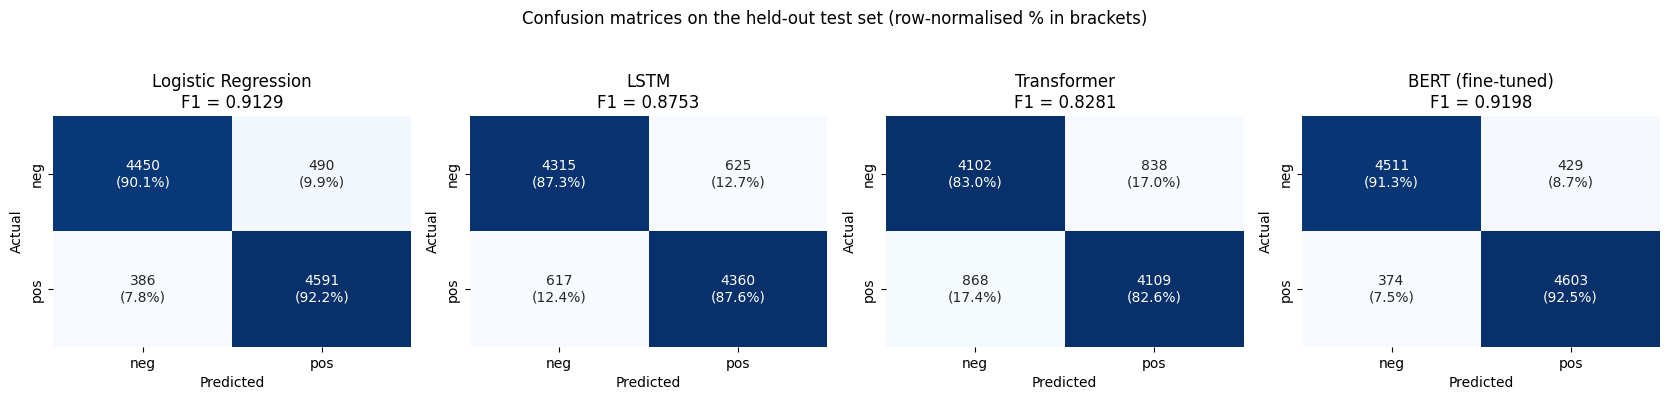

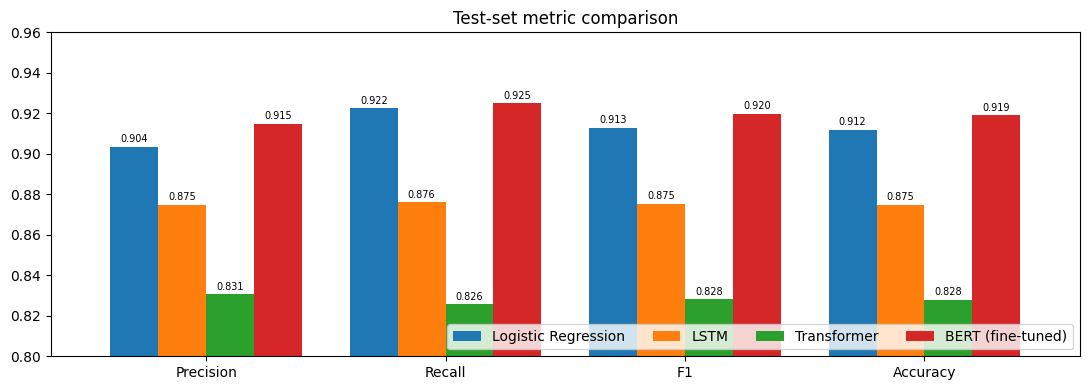

                     False Positives  False Negatives
Logistic Regression              490              386
LSTM                             625              617
Transformer                      838              868
BERT (fine-tuned)                429              374


In [11]:
fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.8))
for ax, (name, r) in zip(axes, results.items()):
    cm = r['cm']
    annot = np.array([[f'{v}\n({v / cm[i].sum():.1%})' for v in row] for i, row in enumerate(cm)])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['neg', 'pos'], yticklabels=['neg', 'pos'])
    ax.set(title=f'{name}\nF1 = {r["F1"]:.4f}', xlabel='Predicted', ylabel='Actual')
plt.suptitle('Confusion matrices on the held-out test set (row-normalised % in brackets)', y=1.04)
plt.tight_layout(); plt.show()

metrics = ['Precision', 'Recall', 'F1', 'Accuracy']
plot_df = pd.DataFrame({k: [v[m] for m in metrics] for k, v in results.items()}, index=metrics)
ax = plot_df.plot.bar(figsize=(11, 4), rot=0, width=0.8)
ax.set_ylim(0.8, 0.96); ax.set_title('Test-set metric comparison'); ax.legend(loc='lower right', ncol=4)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=7, padding=2)
plt.tight_layout(); plt.show()

fp_fn = pd.DataFrame({k: {'False Positives': v['cm'][0, 1], 'False Negatives': v['cm'][1, 0]} for k, v in results.items()}).T
print(fp_fn)

**Interpretation:**
* **Ranking (F1):** **BERT (`0.9198`) > Logistic Regression (`0.9129`) > BiLSTM (`0.8753`) > Vanilla Transformer (`0.8281`)**.
* **Transfer Learning Advantage (BERT):** Fine-tuning `bert-base-uncased` for 1 epoch achieves the highest Precision (`0.9147`), Recall (`0.9249`), F1 (`0.9198`), and Accuracy (`0.9190`), while yielding the fewest False Positives (`429`) and False Negatives (`374`). Pretraining on billions of words provides rich contextual semantics and WordPiece coverage before seeing a single sentiment label.
* **Why TF-IDF + Logistic Regression Beats From-Scratch Neural Models:** With unigrams + bigrams (`100K` features) over full-length reviews, Logistic Regression reaches `0.9129` F1 in `32s` (`0.10M` weights), whereas the from-scratch BiLSTM and Transformer are capped at `256` tokens (`20K` vocab) and must learn word embeddings and syntax simultaneously from `35.7K` examples.
* **Inductive Bias (BiLSTM vs. Vanilla Transformer From Scratch):** With almost identical parameter counts (`2.82M` vs. `2.83M`), the BiLSTM outperforms the Vanilla Transformer by `+4.72` F1 points (`0.8753` vs. `0.8281`). Recurrence provides a strong sequential locality bias on medium-sized datasets, whereas self-attention has no built-in locality and starts overfitting after epoch 3 (`val F1 = 0.8269`) without large-scale pretraining.